# Trabajo final
## Clasificación de perros y gatos

Este notebook es la base común del trabajo.


**Al final de la clase:** rellenad unas preguntas vía MiAulario y entregad una copia del notebook generado.


## 0. Configuración

In [27]:
import os, glob, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from comprobaciones import comprobar_evaluar
# fichero comprobaciones.py, junto a este notebook

RUTA_DATASET = "dataset"      # carpeta con train/ y test/
CARPETA_CACHE = "cache"       # aquí se guardan los vectores ya calculados
CLASES = ["cat", "dog"]       # 0 = gato, 1 = perro
os.makedirs(CARPETA_CACHE, exist_ok=True)

## 1. Lectura del dataset

Estructura esperada:

```
dataset/
├── train/
│   ├── cat/
│   └── dog/
└── test/
    ├── cat/
    └── dog/
```

La etiqueta de cada imagen sale del nombre de su carpeta: 0 = gato, 1 = perro.

In [7]:
def listar_imagenes(carpeta):
    rutas, etiquetas = [], []
    for etiqueta, clase in enumerate(CLASES):
        ficheros = sorted(glob.glob(os.path.join(carpeta, clase, "*")))
        rutas += ficheros
        etiquetas += [etiqueta] * len(ficheros)
    return rutas, np.array(etiquetas)

rutas_train, y_train = listar_imagenes(os.path.join(RUTA_DATASET, "train"))
rutas_test, y_test = listar_imagenes(os.path.join(RUTA_DATASET, "test"))
print(f"Entrenamiento: {len(rutas_train)} imágenes ({np.sum(y_train == 0)} gatos, {np.sum(y_train == 1)} perros)")
print(f"Test:          {len(rutas_test)} imágenes ({np.sum(y_test == 0)} gatos, {np.sum(y_test == 1)} perros)")

Entrenamiento: 2000 imágenes (1000 gatos, 1000 perros)
Test:          2000 imágenes (1000 gatos, 1000 perros)


¿Tienen todas las imágenes el mismo tamaño?

Anchos entre 42 y 1050 · altos entre 39 y 768


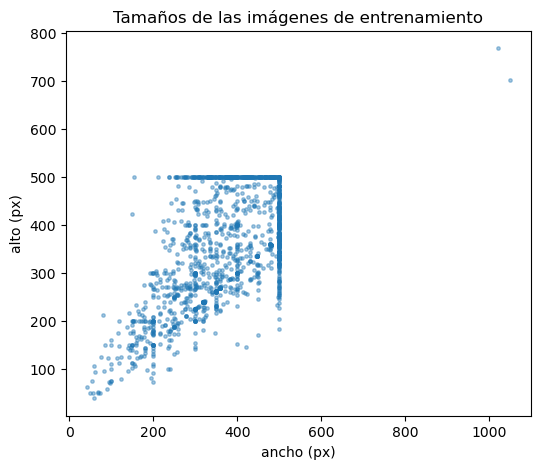

In [8]:
tamanos = np.array([Image.open(r).size for r in rutas_train])   # (ancho, alto), sin decodificar la imagen
plt.figure(figsize=(6, 5))
plt.scatter(tamanos[:, 0], tamanos[:, 1], s=6, alpha=0.4)
plt.xlabel("ancho (px)"); plt.ylabel("alto (px)")
plt.title("Tamaños de las imágenes de entrenamiento")
print("Anchos entre", tamanos[:, 0].min(), "y", tamanos[:, 0].max(), "· altos entre", tamanos[:, 1].min(), "y", tamanos[:, 1].max())

Pensad en esto: ¿el tamaño del descriptor depende del tamaño de la imagen? Todas las imágenes tienen que acabar dando un vector **de la misma longitud**.

## 2. Preprocesado

El preprocesado recibe una imagen BGR tal como la lee OpenCV y devuelve la imagen que verá el descriptor.

Debes decidir si quieres hacer un redimensionado (y a qué dimensión) Después, decidiréis qué otras técnicas de preprocesado podéis utilizar: cambiar de espacio de color, ecualizar, corregir gamma, suavizar… **Un preprocesado no es bueno o malo en abstracto: depende de lo que mide el descriptor.**

In [9]:
def redimensionar(img, tamano=(128, 128)):
    """Redimensiona una imagen BGR al tamaño (ancho, alto) indicado."""
    if isinstance(tamano, int):
        tamano = (tamano, tamano)
    ancho, alto = tamano
    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if (ancho < w or alto < h) else cv2.INTER_LINEAR
    return cv2.resize(img, (ancho, alto), interpolation=interp)

In [10]:
def preprocesar(img):
    # TODO: devolved la imagen preprocesada que irá directamente al extractor de características
    img=redimensionar(img)
    return img

## 3. Paso 1: histograma de color global

Implementad `descriptor_color(img, ...)`. Debe devolver un vector 1D de **longitud fija**, la misma para todas las imágenes, sea cual sea su tamaño. El tamaño del vector vendrá determinado por el número de bins del histograma. Puedes utilizar ese número como parámetro de la función.

Las decisiones son vuestras y tendréis que justificarlas: cuántos intervalos por canal, si los canales van por separado o juntos, si normalizáis el histograma y cómo…

In [18]:
def descriptor_color(img, bins=8):
    histogramas = []
    for c in range(3):
        hist = cv2.calcHist([img], [c], None, [bins], [0, 256]).ravel()
        hist = hist / (hist.sum() + 1e-8)
        histogramas.append(hist)
    return np.concatenate(histogramas)

In [12]:
def sin_preprocesado(img):
    return img

In [19]:
# Comprobación rápida: mismo tamaño de vector para imágenes de tamaños distintos
vectores = [descriptor_color(sin_preprocesado(cv2.imread(r))) for r in rutas_train[:5]]
assert all(np.asarray(v).ndim == 1 for v in vectores), "El descriptor debe devolver un vector 1D"
assert len({np.asarray(v).size for v in vectores}) == 1, "Todas las imágenes deben dar un vector de la misma longitud"
print("Dimensión del vector:", np.asarray(vectores[0]).size)

Dimensión del vector: 24


## 3b. Paso 2: histograma de color por regiones

Dividid la imagen **ya redimensionada** en una rejilla de n × n bloques, calculad vuestro histograma de color en cada uno y concatenad los resultados.


In [20]:
def descriptor_color_regiones(img, n=2):
    bloques = []
    for fila in np.array_split(img, n, axis=0):
        for bloque in np.array_split(fila, n, axis=1):
            bloques.append(descriptor_color(bloque))
    return np.concatenate(bloques)

In [21]:
vectores = [descriptor_color_regiones(redimensionar(cv2.imread(r))) for r in rutas_train[:5]]
assert len({np.asarray(v).size for v in vectores}) == 1, "Todas las imágenes deben dar un vector de la misma longitud"
print("Dimensión del vector por regiones:", np.asarray(vectores[0]).size)

Dimensión del vector por regiones: 96


## 4. Extracción de características (hecho)

`extraer_todas` aplica el preprocesado y el descriptor a una lista de imágenes y devuelve la matriz **X**, con una fila por imagen.

La extracción es la parte lenta, así que guarda el resultado en disco: si la volvéis a llamar con el mismo `nombre`, carga el fichero en lugar de recalcular. **Si cambiáis el preprocesado o el descriptor, cambiad también el nombre** (o borrad el fichero de `cache/`); si no, seguiréis usando los vectores antiguos.

In [16]:
def extraer_todas(rutas, preprocesar, descriptor, nombre=None):
    fichero = os.path.join(CARPETA_CACHE, nombre + ".npy") if nombre else None
    if fichero and os.path.exists(fichero):
        X = np.load(fichero)
        print(f"Cargado de caché: {fichero}  {X.shape}")
        return X
    t0 = time.time()
    filas = []
    for r in rutas:
        img = cv2.imread(r)
        if img is None:
            raise IOError(f"No se puede leer {r}")
        filas.append(np.asarray(descriptor(preprocesar(img)), dtype=np.float32).ravel())
    longitudes = {f.size for f in filas}
    if len(longitudes) > 1:
        raise ValueError(f"El descriptor devuelve vectores de longitudes distintas: {sorted(longitudes)}")
    X = np.vstack(filas)
    if fichero:
        np.save(fichero, X)
    print(f"{len(rutas)} imágenes · vector de {X.shape[1]} dimensiones · {time.time() - t0:.1f} s")
    return X

## 5. Protocolo de evaluación común

Todas las parejas evaluamos igual:

- **Particiones:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=0)`
- **Modelo:** `StandardScaler` + `SVC(kernel="rbf", C=1, gamma="scale")`, sin ajustar C ni gamma
- **El escalado se ajusta solo con la parte de entrenamiento de cada partición.** Si se ajusta con todos los datos, información de la parte de validación se cuela en el entrenamiento.
- `evaluar` devuelve un array con el acierto de cada una de las 5 particiones, en orden.

Completad `evaluar` y ejecutad después `comprobar_evaluar(evaluar)`: compara vuestros resultados con los del protocolo sobre un conjunto sintético y, si no coinciden, os dice qué puede estar fallando.

In [28]:
def evaluar(X, y):
    particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    aciertos = []
    for idx_train, idx_val in particiones.split(X, y):
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[idx_train])
        X_val = scaler.transform(X[idx_val])

        modelo = SVC(kernel="rbf", C=1, gamma="scale")
        modelo.fit(X_train, y[idx_train])
        aciertos.append(modelo.score(X_val, y[idx_val]))
    return np.array(aciertos)
comprobar_evaluar(evaluar)

OK: evaluar coincide con el protocolo (0.8050 ± 0.0812).


## 6. Experimentos del día

Piensa en posibles experimentos:
- ¿afecta la redimensión de la imagen al histograma de color?
- ¿cómo cambia la predicción en función del número de bins?
- ¿aporta algo la división en regiones?
- ¿cómo afecta la ecualización del histograma u otras técnicas al resultado?